In [28]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
# Import libraries
import cv2 as cv

In [30]:
# Import modules
import config
from pipeline import (
    build_detector,
    build_matcher,
    extract_features,
    match_descriptors,
)
from utils import (
    center_crop_to_size,
    grab_frame,
    load_image,
    plot_image,
    plot_keypoints,
    plot_matches,
    shrink_to_max_side,
)

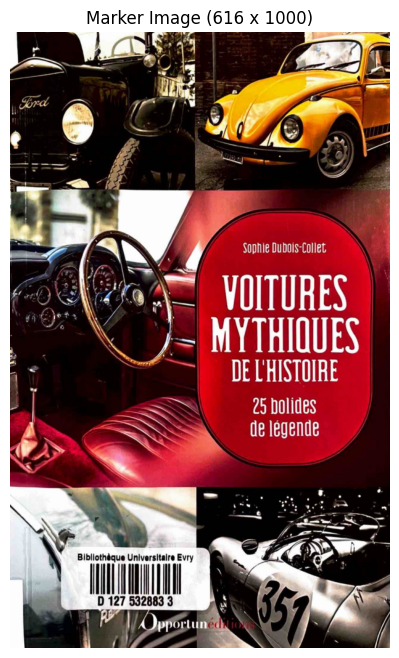

In [31]:
# Marker image
marker = load_image(config.MARKER_PATH)
marker = shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

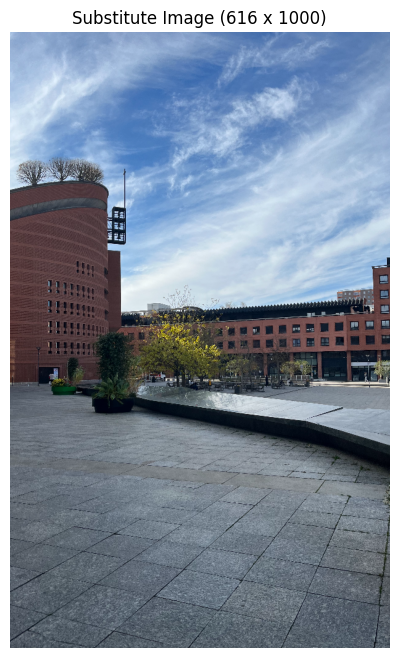

In [32]:
# Substitute image
substitute = load_image(config.SUBSTITUTE_PATH)
substitute = center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
plot_image(substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})")

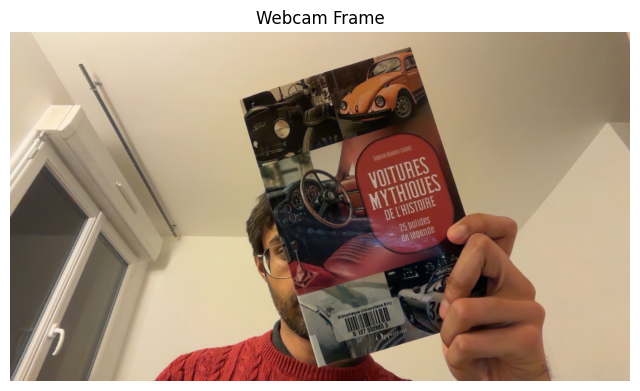

In [33]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, grab_frame(config.CAMERA_INDEX))
frame = load_image(config.FRAME_PATH)
plot_image(frame, "Webcam Frame")

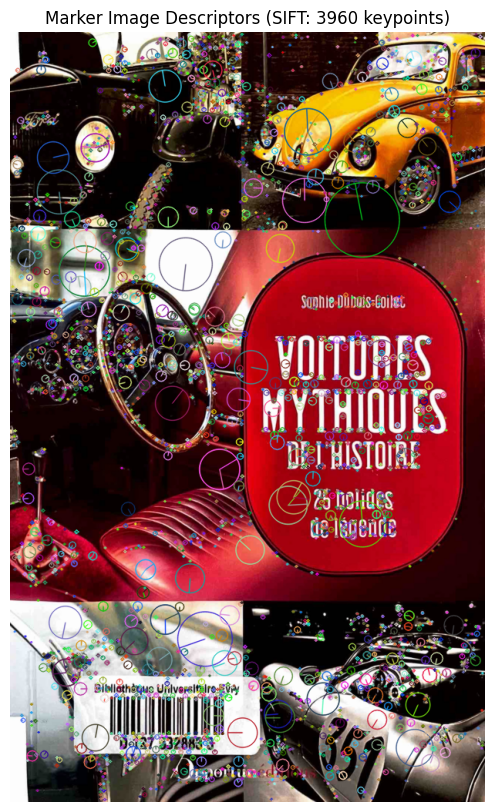

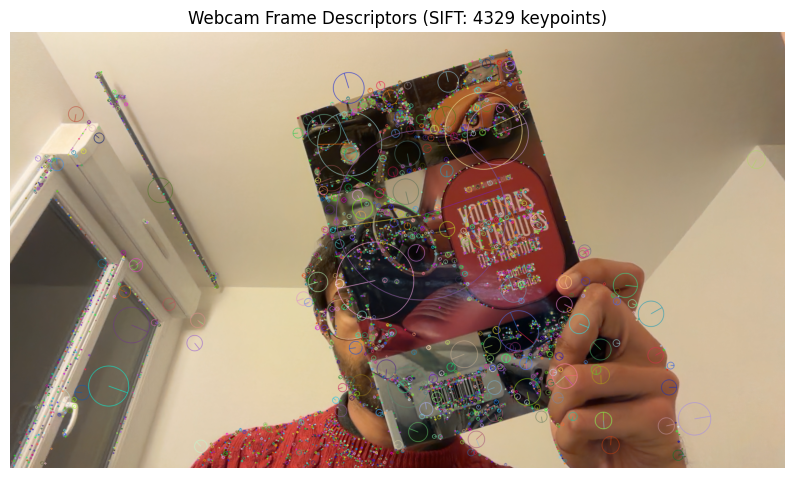

In [34]:
# Image descriptor extraction
detector = build_detector(config.DETECTOR_NAME)

# Marker keypoints
marker_keypoints, marker_descriptors = extract_features(detector, marker)
plot_keypoints(
    marker,
    marker_keypoints,
    f"Marker Image Descriptors ({config.DETECTOR_NAME}: {len(marker_keypoints)} keypoints)",
    10
)

# Frame keypoints
frame_keypoints, frame_descriptors = extract_features(detector, frame)
plot_keypoints(
    frame,
    frame_keypoints,
    f"Webcam Frame Descriptors ({config.DETECTOR_NAME}: {len(frame_keypoints)} keypoints)",
    10
)

3960 marker descriptors matched


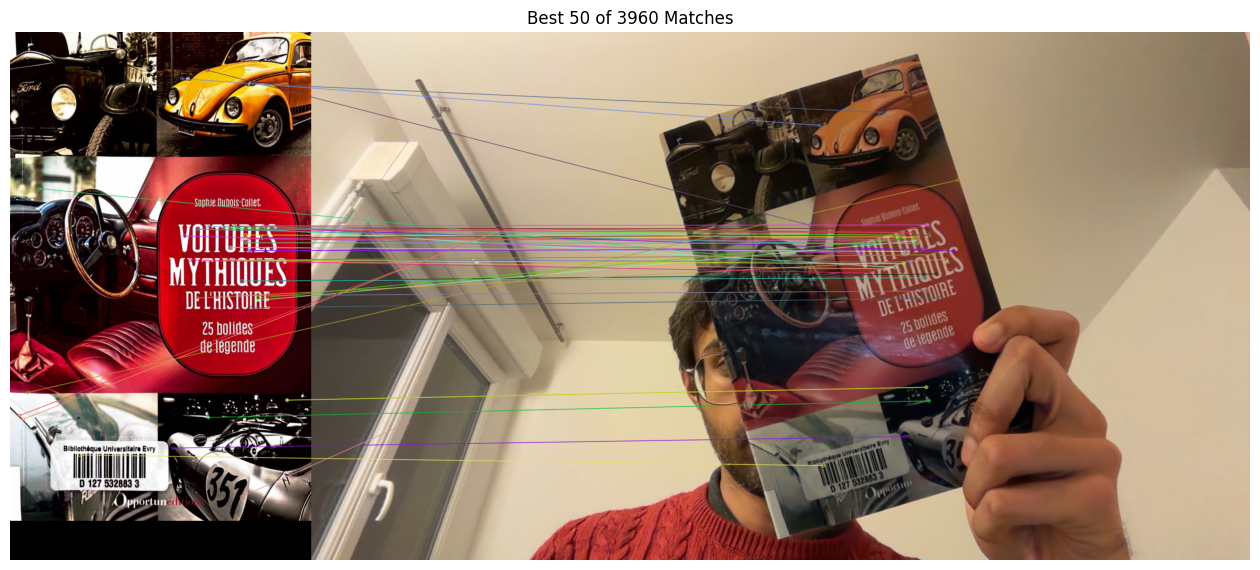

In [35]:
# Descriptor matching
matcher = build_matcher(config.MATCHER_NAME, config.DETECTOR_NAME)
knn_matches = match_descriptors(matcher, marker_descriptors, frame_descriptors)
print(f"{len(knn_matches)} marker descriptors matched")

# Best candidate for each keypoint
best_matches = []
for candidates in knn_matches:
    if candidates:
        best_matches.append(candidates[0])

# Sort by distance
best_matches.sort(key=lambda match: match.distance)

# Plot only the closest matches
shown_matches = 50
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    best_matches[:shown_matches],
    f"Best {shown_matches} of {len(best_matches)} Matches",
)